# Budget-forcing SFT and evaluation

This Colab notebook fine-tunes DeepSeek-R1-Distill-Qwen-1.5B with the existing train split, evaluates the test split at 0 and 2 forced continuations, plots loss and test metrics, and downloads a package containing the adapter, JSON metrics, and plots.

Upload `train.json` and `test.json` to `/content`, or upload the package's `budget_forcing/` folder. Results are written directly under `/content`. The base model is downloaded into `/content/base_model_weights` when not already cached. Training uses a T4-compatible QLoRA configuration; only LoRA adapter parameters are trainable.

## 1. Install dependencies

Install Transformers, PEFT, bitsandbytes, and plotting utilities. If Colab asks for a restart, restart once and rerun from this cell.

In [1]:
!pip -q install -U transformers accelerate bitsandbytes peft matplotlib tqdm


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 106.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 127.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 7.2 MB/s eta 0:00:00


## 2. Configure the run and verify the T4

All inputs and outputs live directly under `/content`. Upload final `train.json` and `test.json` before running. The notebook refuses CPU execution because it would exceed the intended runtime.

In [2]:
import json, random, re, shutil, tempfile, time
from collections import defaultdict
from decimal import Decimal, InvalidOperation
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset
from tqdm.auto import tqdm
from huggingface_hub import snapshot_download
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, Trainer, TrainingArguments
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

ROOT = Path('/content')
PACKAGE_DIR = ROOT / 'budget_forcing'
PACKAGE_LAYOUT_DIR = ROOT / 'budget-force-reasoning' / 'budget_forcing'
BASE_MODEL_DIR = ROOT / 'base_model_weights'
MODEL_ID = 'deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B'
ADAPTER_DIR = ROOT / 'sft_qlora'
SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
assert torch.cuda.is_available(), 'Select a GPU runtime before continuing.'
print('GPU:', torch.cuda.get_device_name(0))

def find_input(filename):
    candidates = [ROOT / filename, PACKAGE_DIR / filename, PACKAGE_LAYOUT_DIR / filename, Path.cwd() / filename]
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f'Upload {filename} to /content or /content/budget_forcing.')

TRAIN_PATH = find_input('train.json')
TEST_PATH = find_input('test.json')

GPU: Tesla T4


## 3. Download the public base model and validate data

The model snapshot is downloaded only when absent. The final schema and reasoning-step cap are checked before GPU memory is allocated.

In [3]:
BASE_MODEL_DIR.mkdir(parents=True, exist_ok=True)
if not (BASE_MODEL_DIR / 'config.json').is_file():
    print('Downloading base model. T4 ETA: typically 5-15 minutes, depending on network speed.')
    snapshot_download(repo_id=MODEL_ID, local_dir=BASE_MODEL_DIR)
else:
    print('Using cached base model; download ETA: 0 minutes.')

def load_final(path):
    rows = json.loads(path.read_text(encoding='utf-8'))
    required = {'id', 'x_i', 'r_i', 'y_i', 'topic'}
    for row in rows:
        assert required.issubset(row), f'Malformed record: {row.get("id")}'
        assert isinstance(row['r_i'], list) and 0 < len(row['r_i']) <= 20
    return rows

train_rows = load_final(TRAIN_PATH)
test_rows = load_final(TEST_PATH)
print('Train size:', len(train_rows))
print('Test size:', len(test_rows))
assert len(train_rows) == 450 and len(test_rows) == 90

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_DIR, local_files_only=True)
tokenizer.pad_token = tokenizer.pad_token or tokenizer.eos_token
tokenizer.padding_side = 'left'

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Train size: 450
Test size: 90


## 4. Format supervised examples

Questions form the prompt. Only `<think>` and `<final>` completion tokens receive loss; prompt and padding labels are `-100`. The 1,024-token cap reduces T4 time and memory while remaining ample for these concise traces.

In [4]:
MAX_LENGTH = 1024

def encode_record(row):
    prompt = f"Question: {row['x_i']}\n\n"
    completion = '<think>\n' + '\n'.join(row['r_i']) + f"\n</think>\n<final>\n{row['y_i']}\n</final>"
    encoded = tokenizer(prompt + completion, truncation=True, max_length=MAX_LENGTH)
    prompt_length = len(tokenizer(prompt, truncation=True, max_length=MAX_LENGTH)['input_ids'])
    labels = encoded['input_ids'].copy()
    labels[:min(prompt_length, len(labels))] = [-100] * min(prompt_length, len(labels))
    return {'input_ids': encoded['input_ids'], 'attention_mask': encoded['attention_mask'], 'labels': labels}

class ReasoningDataset(Dataset):
    def __len__(self): return len(train_rows)
    def __getitem__(self, index): return encode_record(train_rows[index])

def collate(batch):
    width = max(len(item['input_ids']) for item in batch)
    fills = {'input_ids': tokenizer.pad_token_id, 'attention_mask': 0, 'labels': -100}
    return {key: torch.tensor([item[key] + [fill] * (width - len(item[key])) for item in batch]) for key, fill in fills.items()}

train_dataset = ReasoningDataset()
print('First encoded length:', len(train_dataset[0]['input_ids']))


First encoded length: 249


## 5. Load 4-bit DeepSeek and attach LoRA

NF4 quantization fits the base model on a T4. Rank 32 gives the adapter more capacity than the earlier run. Only adapter parameters train; this is QLoRA, not full-parameter SFT.

In [5]:
quantization = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
model = AutoModelForCausalLM.from_pretrained(BASE_MODEL_DIR, local_files_only=True, quantization_config=quantization, device_map='auto')
model = prepare_model_for_kbit_training(model)
model = get_peft_model(model, LoraConfig(r=32, lora_alpha=64, lora_dropout=0.05, bias='none', task_type='CAUSAL_LM', target_modules=['q_proj','k_proj','v_proj','o_proj','gate_proj','up_proj','down_proj']))
model.config.use_cache = False
model.print_trainable_parameters()

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

trainable params: 36,929,536 || all params: 1,814,017,536 || trainable%: 2.0358


## 6. Train for six epochs

Batch 1 with accumulation 16 gives effective batch 16. The lower `5e-5` learning rate is conservative; six epochs allow more fitting. No target loss is guaranteed, and test accuracy remains the deciding metric.

In [6]:
training_args = TrainingArguments(output_dir=str(ADAPTER_DIR), num_train_epochs=6, per_device_train_batch_size=1, gradient_accumulation_steps=16, learning_rate=5e-5, optim='paged_adamw_8bit', fp16=True, bf16=False, warmup_steps=10, lr_scheduler_type='cosine', logging_strategy='steps', logging_steps=5, logging_first_step=False, save_strategy='epoch', save_total_limit=2, report_to=[], remove_unused_columns=False, disable_tqdm=False)
trainer = Trainer(model=model, args=training_args, train_dataset=train_dataset, data_collator=collate)
print('Starting QLoRA training. Typical T4 ETA: 25-35 minutes. The Trainer progress bar shows the live ETA.')
training_started = time.time()
trainer.train()
TRAINING_MINUTES = (time.time() - training_started) / 60
print('Training minutes:', TRAINING_MINUTES)
model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)


Starting QLoRA training. Typical T4 ETA: 25-35 minutes. The Trainer progress bar shows the live ETA.


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss
5,1.208165
10,1.042859
15,0.806593
20,0.716936
25,0.653819
30,0.580687
35,0.608689
40,0.567514
45,0.566489
50,0.567431


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/pyt

Training minutes: 25.990808816750846


('/content/sft_qlora/tokenizer_config.json',
 '/content/sft_qlora/chat_template.jinja',
 '/content/sft_qlora/tokenizer.json')

## 7. Plot optimizer-step loss

Plot logged loss against optimizer steps, which is more precise than joining sparse epoch points.

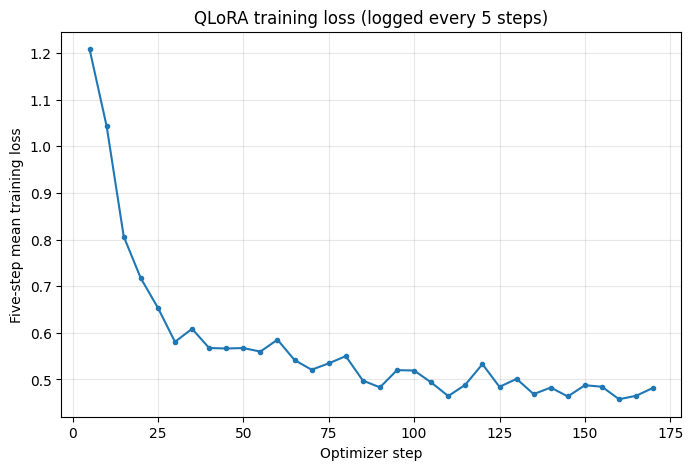

In [7]:
# Trainer reports the mean loss over each five-step logging interval; raw per-step losses are not displayed.
loss_history = [entry for entry in trainer.state.log_history if 'loss' in entry and entry['step'] % 5 == 0]
plt.figure(figsize=(8,5)); plt.plot([x['step'] for x in loss_history], [x['loss'] for x in loss_history], marker='o', markersize=3)
plt.xlabel('Optimizer step'); plt.ylabel('Five-step mean training loss'); plt.title('QLoRA training loss (logged every 5 steps)'); plt.grid(alpha=.3)
plt.savefig(ROOT/'sft_loss.png', dpi=160, bbox_inches='tight'); plt.show()


## 8. Define batched budget-forcing inference

All 90 test records are processed in GPU batches of 16. Each reasoning call may use the complete remaining 1,024-token budget. `Wait` is inserted only when the model attempts `<final>` or emits EOS; generating `</think>` alone is not counted as a forcing event. Both configurations share the same 1,024-token reasoning cap and 32-token final-answer allowance.

In [8]:
model.config.use_cache = True; model.eval()
BATCH_SIZE = 16
SEGMENT_TOKENS = 1024      # Per-call ceiling; the actual call uses only the remaining total budget.
ANSWER_TOKENS = 32         # Separate allowance for the final numeric answer.
THINKING_BUDGET = 1024     # Shared maximum model-produced reasoning tokens per example.
def canonical(value):
    try:
        number = Decimal(str(value).strip().replace(',', '').replace('$', ''))
    except InvalidOperation:
        return None
    if not number.is_finite():
        return None
    text = format(number.normalize(), 'f')
    if '.' in text:
        text = text.rstrip('0').rstrip('.')
    return '0' if text in ('', '-0') else text

def batch_generate(prompts, max_tokens, stop_on_reasoning_end=False):
    encoded = tokenizer(prompts, return_tensors='pt', padding=True, truncation=True, max_length=3072).to(model.device)
    generation_options = dict(do_sample=False, max_new_tokens=max_tokens, pad_token_id=tokenizer.eos_token_id, eos_token_id=tokenizer.eos_token_id)
    if stop_on_reasoning_end:
        # Do not stop on </think> alone. Force only when the model attempts its final answer.
        generation_options.update(stop_strings=['<final>'], tokenizer=tokenizer)
    with torch.inference_mode():
        output = model.generate(**encoded, **generation_options)
    prompt_width = encoded['input_ids'].shape[1]
    eos_ids = {tokenizer.eos_token_id} if isinstance(tokenizer.eos_token_id, int) else set(tokenizer.eos_token_id or [])
    generated = []
    for i in range(len(prompts)):
        token_ids = output[i, prompt_width:].tolist()
        text = tokenizer.decode(token_ids, skip_special_tokens=True)
        marker_stop = '<final>' in text
        eos_stop = any(token_id in eos_ids for token_id in token_ids)
        generated.append({'text': text, 'naturally_stopped': marker_stop or eos_stop})
    return generated

def split_at_reasoning_stop(text):
    # Intercept <final>, then remove an immediately preceding </think> from the retained prefix.
    final_position = text.find('<final>')
    if final_position >= 0:
        reasoning = text[:final_position].rstrip()
        reasoning = re.sub(r'\s*</think>\s*$', '', reasoning).rstrip()
        return reasoning, True
    return text.rstrip(), False

def evaluate_configuration(num_ignore):
    results = []
    for start in tqdm(range(0, len(test_rows), BATCH_SIZE), desc=f'ignore={num_ignore}'):
        batch = test_rows[start:start + BATCH_SIZE]
        prefixes = [f"Question: {row['x_i']}\n\n<think>\n" for row in batch]
        thinking = [''] * len(batch)
        counts = [0] * len(batch)
        forced = [0] * len(batch)
        completed = [False] * len(batch)

        # Only unfinished examples remain active. This is both faster and faithful to budget forcing.
        active = list(range(len(batch)))
        while active:
            prompts = [prefixes[i] + thinking[i] for i in active]
            chunk_limit = min(SEGMENT_TOKENS, max(THINKING_BUDGET - counts[i] for i in active))
            segments = batch_generate(prompts, chunk_limit, stop_on_reasoning_end=True)
            still_active = []
            for i, generated in zip(active, segments):
                segment, marker_stop = split_at_reasoning_stop(generated['text'])
                reached_stop = marker_stop or generated['naturally_stopped']
                segment_ids = tokenizer.encode(segment, add_special_tokens=False)
                remaining = THINKING_BUDGET - counts[i]
                truncated_by_budget = len(segment_ids) > remaining
                if truncated_by_budget:
                    segment_ids = segment_ids[:remaining]
                    segment = tokenizer.decode(segment_ids, skip_special_tokens=True)
                    # A final/EOS beyond the allowed budget is not a valid in-budget stop.
                    reached_stop = False
                thinking[i] += segment
                counts[i] += len(segment_ids)
                if reached_stop:
                    # EOS may follow </think> without <final>; keep tags out of the continued reasoning prefix.
                    thinking[i] = re.sub(r'\s*</think>\s*$', '', thinking[i]).rstrip()

                if not segment_ids and not reached_stop:
                    # An immediate EOS without a closing tag is malformed; do not loop forever.
                    continue
                if reached_stop and forced[i] < num_ignore and counts[i] < THINKING_BUDGET:
                    thinking[i] += '\nWait\n'
                    forced[i] += 1
                    still_active.append(i)
                elif reached_stop:
                    completed[i] = True
                elif counts[i] < THINKING_BUDGET:
                    still_active.append(i)
            active = still_active

        answer_prompts = [prefixes[i] + thinking[i] + '\n</think>\n<final>\n' for i in range(len(batch))]
        answers = [item['text'] for item in batch_generate(answer_prompts, ANSWER_TOKENS)]
        for i, (row, answer) in enumerate(zip(batch, answers)):
            numbers = re.findall(r'(?<![\w.])-?\$?[\d,]+(?:\.\d+)?', answer)
            prediction = canonical(numbers[-1]) if numbers else None
            malformed = prediction is None or '</think>' in thinking[i] or '<final>' in thinking[i]
            error_flags = {
                'missing_answer': prediction is None,
                'incomplete_forcing': forced[i] != num_ignore,
                'thinking_budget_exhausted': counts[i] >= THINKING_BUDGET and not completed[i],
                'malformed_reasoning': '</think>' in thinking[i] or '<final>' in thinking[i],
            }
            control = counts[i] <= THINKING_BUDGET and completed[i] and forced[i] == num_ignore and not malformed
            results.append({
                'id': row['id'], 'topic': row['topic'], 'expected_answer': canonical(row['y_i']),
                'extracted_answer': prediction, 'correct': prediction == canonical(row['y_i']),
                'thinking_tokens': counts[i], 'forced_continuations': forced[i],
                'requested_continuations': num_ignore, 'control': control, 'error_flags': error_flags,
                'trace': '<think>\n' + thinking[i] + '\n</think>\n<final>\n' + answer,
            })
    return results


## 9. Evaluate all 90 tests at 0 and 2 continuations

This is the longest evaluation cell. Progress bars show that it is active. Results are saved after every configuration, so a later interruption does not discard completed work.

In [9]:
predictions={}; summary={}; evaluation_started=time.time()
evaluation_estimates={0:'15-25 minutes',2:'30-55 minutes'}
for ignored in (0,2):
    print(f'Starting ignore={ignored}. Typical T4 ETA: {evaluation_estimates[ignored]}. The progress bar shows the live ETA.')
    rows=evaluate_configuration(ignored); predictions[str(ignored)]=rows
    summary[str(ignored)]={'accuracy':sum(x['correct'] for x in rows)/len(rows),'correct':sum(x['correct'] for x in rows),'total':len(rows),'control':sum(x['control'] for x in rows)/len(rows),'average_thinking_tokens':sum(x['thinking_tokens'] for x in rows)/len(rows)}
    (ROOT/'sft_budget_results.partial.json').write_text(json.dumps({'summary':summary,'predictions':predictions},indent=2),encoding='utf-8')
print('Evaluation minutes:',(time.time()-evaluation_started)/60)


Starting ignore=0. Typical T4 ETA: 15-25 minutes. The progress bar shows the live ETA.


ignore=0:   0%|          | 0/6 [00:00<?, ?it/s]

Starting ignore=2. Typical T4 ETA: 30-55 minutes. The progress bar shows the live ETA.


ignore=2:   0%|          | 0/6 [00:00<?, ?it/s]

Evaluation minutes: 35.54573640426


## 10. Compute plan metrics and plots

Create accuracy, control, compute-scaling, and per-topic accuracy plots. The notebook also reports the honest 2-cycle minus 0-cycle accuracy difference; a positive result is measured rather than enforced.

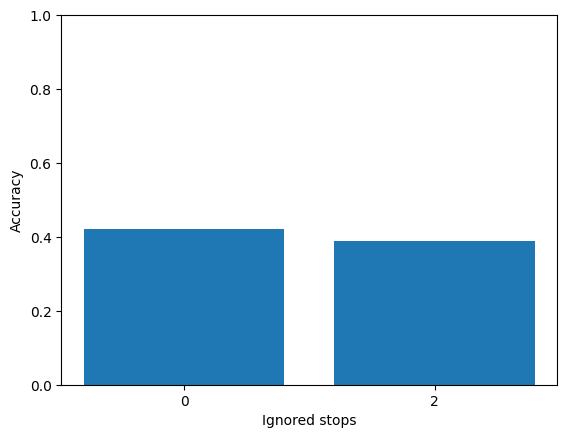

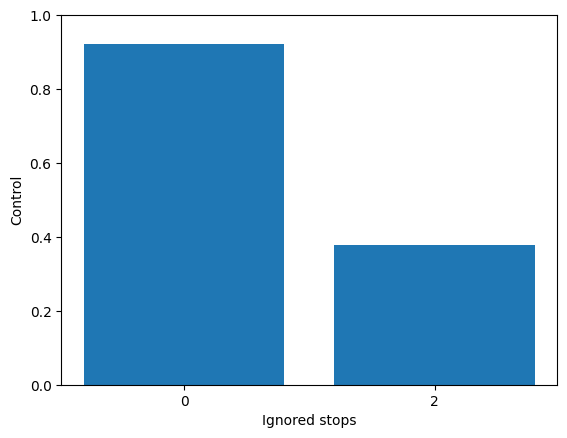

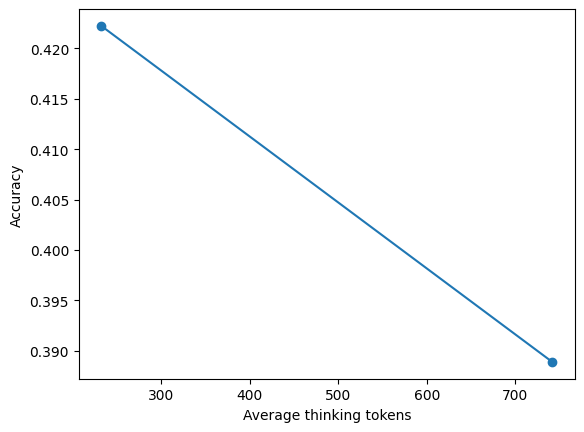

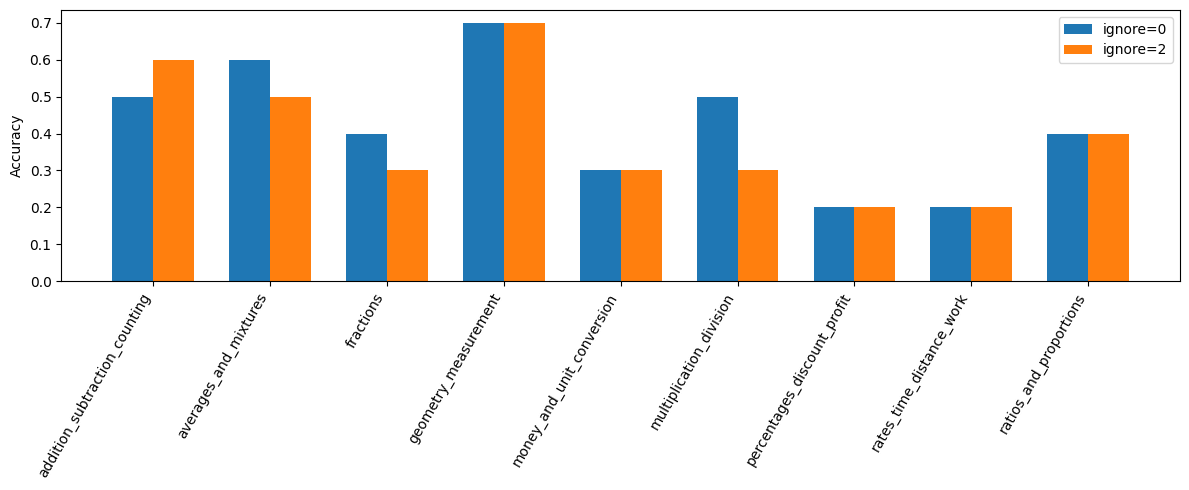

{
  "0": {
    "accuracy": 0.4222222222222222,
    "correct": 38,
    "total": 90,
    "control": 0.9222222222222223,
    "average_thinking_tokens": 232.54444444444445
  },
  "2": {
    "accuracy": 0.3888888888888889,
    "correct": 35,
    "total": 90,
    "control": 0.37777777777777777,
    "average_thinking_tokens": 741.6
  },
  "scaling_slope": -6.54807377496453e-05,
  "accuracy_gain_2_vs_0": -0.033333333333333326,
  "two_cycle_improved": false
}


In [10]:
configs=['0','2']; tokens=[summary[c]['average_thinking_tokens'] for c in configs]; accuracies=[summary[c]['accuracy'] for c in configs]
summary['scaling_slope']=(accuracies[-1]-accuracies[0])/(tokens[-1]-tokens[0]) if tokens[-1]!=tokens[0] else None
summary['accuracy_gain_2_vs_0']=summary['2']['accuracy']-summary['0']['accuracy']
summary['two_cycle_improved']=summary['accuracy_gain_2_vs_0']>0
topics=sorted({r['topic'] for r in test_rows}); per_topic={}
for c in configs: per_topic[c]={t:sum(x['correct'] for x in predictions[c] if x['topic']==t)/sum(1 for x in predictions[c] if x['topic']==t) for t in topics}
for name,values,ylabel in [('accuracy_comparison',[summary[c]['accuracy'] for c in configs],'Accuracy'),('control_comparison',[summary[c]['control'] for c in configs],'Control')]:
    plt.figure(); plt.bar(configs,values); plt.xlabel('Ignored stops'); plt.ylabel(ylabel); plt.ylim(0,1); plt.savefig(ROOT/f'{name}.png',dpi=160,bbox_inches='tight'); plt.show()
plt.figure(); plt.plot(tokens,accuracies,'o-'); plt.xlabel('Average thinking tokens'); plt.ylabel('Accuracy'); plt.savefig(ROOT/'scaling_comparison.png',dpi=160,bbox_inches='tight'); plt.show()
plt.figure(figsize=(12,5)); width=.35; xs=range(len(topics))
for j,c in enumerate(configs): plt.bar([x+(j-(len(configs)-1)/2)*width for x in xs],[per_topic[c][t] for t in topics],width,label=f'ignore={c}')
plt.xticks(list(xs),topics,rotation=60,ha='right'); plt.ylabel('Accuracy'); plt.legend(); plt.tight_layout(); plt.savefig(ROOT/'per_topic_accuracy.png',dpi=160); plt.show()
results={'model':MODEL_ID,'method':'QLoRA','summary':summary,'per_topic_accuracy':per_topic,'predictions':predictions}
(ROOT/'sft_budget_results.json').write_text(json.dumps(results,ensure_ascii=False,indent=2)+'\n',encoding='utf-8'); print(json.dumps(summary,indent=2))


## 11. Save and download the run artifacts

This cell saves the adapter files, training/evaluation JSON, and plots in one archive. The base model snapshot is excluded because the notebook can download it again. Extract the archive directly into `budget_forcing/` to keep the adapter files beside these notebooks. The fresh adapter from the earlier run was not included in the prior JSON-only archive, so this corrected cell includes it.

In [11]:
from google.colab import files

training_metrics = {'logging_interval_optimizer_steps': 5, 'loss_history': loss_history, 'training_minutes': TRAINING_MINUTES}
(ROOT/'training_metrics.json').write_text(json.dumps(training_metrics, indent=2)+'\n', encoding='utf-8')
run_info = {'model': MODEL_ID, 'method': 'QLoRA', 'epochs': 6, 'learning_rate': 5e-5,
            'effective_training_batch_size': 16, 'inference_batch_size': BATCH_SIZE,
            'lora_r': 32, 'lora_alpha': 64, 'train_examples': len(train_rows),
            'test_examples': len(test_rows), 'forcing': [0, 2],
            'thinking_budget': THINKING_BUDGET, 'answer_tokens': ANSWER_TOKENS,
            'wait_policy': 'only_on_final_marker_or_eos'}
(ROOT/'run_info.json').write_text(json.dumps(run_info, indent=2)+'\n', encoding='utf-8')

archive_files = ['adapter_config.json', 'adapter_model.safetensors', 'tokenizer.json',
                 'tokenizer_config.json', 'special_tokens_map.json', 'chat_template.jinja']
with tempfile.TemporaryDirectory() as temp_name:
    export = Path(temp_name)
    for filename in archive_files:
        source = ADAPTER_DIR / filename
        if source.is_file():
            shutil.copy2(source, export / filename)
    for filename in ['run_info.json', 'training_metrics.json', 'sft_budget_results.json',
                     'sft_loss.png', 'accuracy_comparison.png', 'control_comparison.png',
                     'scaling_comparison.png', 'per_topic_accuracy.png']:
        source = ROOT / filename
        if source.is_file():
            shutil.copy2(source, export / filename)
    required_weights = ['adapter_config.json', 'adapter_model.safetensors']
    missing_weights = [name for name in required_weights if not (export / name).is_file()]
    if missing_weights:
        raise FileNotFoundError(f'Adapter files missing from export: {missing_weights}')
    archive = shutil.make_archive(str(ROOT/'budget_force_results'), 'zip', export)
print('Created adapter + JSON + plots archive:', archive)
print('Archive creation ETA: under 1 minute.')
files.download(archive)

Created adapter + JSON + plots archive: /content/budget_force_results.zip
Archive creation ETA: under 1 minute.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>